In [1]:
#creditcard

In [ ]:
#Description
"""
This project focuses on detecting fraudulent credit card transactions using machine learning classification techniques.
The dataset contains 284,807 transactions with 30 anonymized PCA-transformed numerical features (V1–V28),
a “Time” feature, an “Amount” feature, and a binary “Class” label (0 = legitimate, 1 = fraud).
The main goal is to correctly classify fraud cases, which are extremely rare in the dataset (only 0.17% of records).
Because of this heavy class imbalance, the Synthetic Minority Oversampling Technique (SMOTE) is applied to balance 
the dataset before training the models.
The analysis includes data exploration, descriptive statistics, visualizations, correlation analysis, skewness/kurtosis 
evaluation, SMOTE balancing, and training several machine learning models including Logistic Regression, Decision Tree 
Classifier, and Gaussian Naive Bayes. Model performance is evaluated using confusion matrices, precision, recall,
F1-score, and cross-validation.
This project demonstrates how machine learning can be applied to highly imbalanced classification problems such as fraud detection.
"""

In [8]:
#Importing the required Python libraries and machine learning modules."
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import RobustScaler

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math
from rich import print
import missingno

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams["figure.figsize"] = (25, 10)

In [2]:
#Data loading and Basic Data Exploration

In [3]:
cc=pd.read_csv("creditcard.csv")

In [4]:
cc.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
cc.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [7]:
cc.sample()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
177435,123174.0,0.094946,0.316992,0.999559,-0.632609,0.150933,0.292397,0.055076,0.247145,0.427582,...,0.325624,1.082196,-0.08372,0.740764,-0.314731,-0.338717,0.080191,0.014286,9.99,0


In [10]:
cc.shape

(284807, 31)

In [11]:
cc.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [12]:
cc.size

8829017

In [13]:
cc.nunique()

Time      124592
V1        275663
V2        275663
V3        275663
V4        275663
V5        275663
V6        275663
V7        275663
V8        275663
V9        275663
V10       275663
V11       275663
V12       275663
V13       275663
V14       275663
V15       275663
V16       275663
V17       275663
V18       275663
V19       275663
V20       275663
V21       275663
V22       275663
V23       275663
V24       275663
V25       275663
V26       275663
V27       275663
V28       275663
Amount     32767
Class          2
dtype: int64

In [14]:
cc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [15]:
cc.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [16]:
cc.describe(include='all')

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [9]:
cc.isna().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [13]:
cc.sample(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
114695,73586.0,-0.522202,-0.896105,2.274563,-1.941693,-1.025694,1.916322,-0.968493,0.686010,-1.724736,...,0.001975,0.583358,0.171199,-0.987994,-0.533928,-0.107837,0.220691,0.115719,72.60,0
281277,170051.0,2.078117,-0.073942,-1.524023,0.069438,0.600155,-0.066645,0.102163,-0.109484,0.219648,...,-0.236415,-0.531078,0.219370,0.128736,-0.089446,0.259247,-0.076702,-0.071244,1.18,0
257111,158008.0,2.128249,-1.374844,-1.707666,-1.852084,1.133511,3.842815,-1.828260,1.022812,0.186773,...,0.431021,1.269103,0.114500,0.761775,-0.069613,0.044401,0.043228,-0.052045,14.95,0
70324,53821.0,1.118017,0.220890,0.357521,1.012600,-0.148512,-0.286977,0.051890,0.042478,-0.278747,...,0.126963,0.374477,-0.067145,0.234085,0.548710,-0.329815,0.023388,0.010918,17.74,0
234798,148121.0,1.987666,-0.247148,-1.342895,0.402325,0.048054,-0.710206,0.041916,-0.188928,0.551912,...,0.153445,0.391142,0.120266,0.694731,-0.048542,0.356351,-0.073496,-0.049357,44.89,0


In [14]:
cc.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

In [16]:
cc.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [17]:
cc["Amount"].value_counts()

Amount
1.00      13688
1.98       6044
0.89       4872
9.99       4747
15.00      3280
          ...  
202.24        1
252.85        1
615.52        1
180.93        1
807.48        1
Name: count, Length: 32767, dtype: int64

In [18]:
cc.head().T

,0,1,2,3,4
Time,0.000000,0.000000,1.000000,1.000000,2.000000
V1,-1.359807,1.191857,-1.358354,-0.966272,-1.158233
V2,-0.072781,0.266151,-1.340163,-0.185226,0.877737
V3,2.536347,0.166480,1.773209,1.792993,1.548718
V4,1.378155,0.448154,0.379780,-0.863291,0.403034
V5,-0.338321,0.060018,-0.503198,-0.010309,-0.407193
V6,0.462388,-0.082361,1.800499,1.247203,0.095921
V7,0.239599,-0.078803,0.791461,0.237609,0.592941
V8,0.098698,0.085102,0.247676,0.377436,-0.270533
V9,0.363787,-0.255425,-1.514654,-1.387024,0.817739


In [20]:
print(cc['Amount'].describe())

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [22]:
print(cc.groupby(['Time','Amount']).size())

Time      Amount
0.0       2.69      1
          149.62    1
1.0       123.50    1
          378.66    1
2.0       3.67      1
                   ..
172786.0  0.77      1
172787.0  24.79     1
172788.0  10.00     1
          67.88     1
172792.0  217.00    1
Length: 279944, dtype: int64

In [24]:
cc.size

8829017

In [27]:
print(cc[['Time','Amount']].head())

Time  Amount
0   0.0  149.62
1   0.0    2.69
2   1.0  378.66
3   1.0  123.50
4   2.0   69.99

In [30]:
print(cc[cc['Amount']>=200].head(10))

Time        V1        V2        V3        V4        V5        V6  \
2     1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499   
20   16.0  0.694885 -1.361819  1.029221  0.834159 -1.191209  1.309109   
51   36.0 -1.004929 -0.985978 -0.038039  3.710061 -6.631951  5.122103   
64   42.0 -0.522666  1.009923  0.276470  1.475289 -0.707013  0.355243   
85   55.0 -4.575093 -4.429184  3.402585  0.903915  3.002224 -0.491078   
89   59.0 -0.773293 -4.146007 -0.932038  0.027094 -1.698307  0.460188   
134  83.0 -1.897331  0.955626  0.052543  1.276656 -3.323084  3.229911   
140  87.0 -5.101877  1.897022 -3.458034 -1.277543 -5.517758  2.098366   
142  89.0  0.270725 -1.615317  1.054982  1.661510 -1.737687  0.065894   
147  92.0  0.607153 -0.957413  0.761505  1.590050 -1.177298  0.011232   

           V7        V8        V9  ...       V21       V22       V23  \
2    0.791461  0.247676 -1.514654  ...  0.247998  0.771679  0.909412   
20  -0.878586  0.445290 -0.446196  ... -0.295583 -0.571955 -0.050881   
51   4.371691 -2.006868 -0.278736  ...  1.393406 -0.381671  0.969719   
64   1.559849 -0.399579 -0.479813  ...  0.172401  1.011543  0.069666   
85  -2.705393  0.666451  1.922216  ... -0.047365  0.853360 -0.971600   
89   0.737344 -0.314216 -0.842673  ...  0.890978  0.026123 -1.134769   
134  1.029631  1.515607 -0.059627  ...  0.128416  0.776078  0.477537   
140  3.329603  1.250966  0.271501  ... -0.871744 -0.678879 -0.555900   
142 -0.313977  0.089081  1.069842  ...  0.475338  0.496083 -0.482194   
147 -0.166991  0.152720  0.742860  ...  0.166237  0.100682 -0.317001   

          V24       V25       V26       V27       V28   Amount  Class  
2   -0.689281 -0.327642 -0.139097 -0.055353 -0.059752   378.66      0  
20  -0.304215  0.072001 -0.422234  0.086553  0.063499   231.71      0  
51   0.019445  0.570923  0.333278  0.857373 -0.075538  1402.95      0  
64   0.157820 -1.109224 -0.302369  0.318170  0.316910   243.66      0  
85  -0.114862  0.408300 -0.304576  0.547785 -0.456297   200.01      0  
89  -0.654958  0.098386 -0.209150 -0.171709  0.208057  1142.02      0  
134 -0.608981 -1.120892 -0.413851  0.061399 -0.187964   552.18      0  
140 -0.761660  0.066611  0.767227  0.731634 -0.860310   919.60      0  
142  0.418871  0.235961 -0.265185 -0.001063  0.120126   459.39      0  
147  0.543778  0.484232 -0.330425 -0.001545  0.062098   268.78      0  

[10 rows x 31 columns]

In [31]:
cc.ndim

2

In [32]:
cc.index

RangeIndex(start=0, stop=284807, step=1)

In [33]:
cc.notnull()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
1,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
2,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
3,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
4,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
284803,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
284804,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
284805,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


In [4]:
cc.max()

Time      172792.000000
V1             2.454930
V2            22.057729
V3             9.382558
V4            16.875344
V5            34.801666
V6            73.301626
V7           120.589494
V8            20.007208
V9            15.594995
V10           23.745136
V11           12.018913
V12            7.848392
V13            7.126883
V14           10.526766
V15            8.877742
V16           17.315112
V17            9.253526
V18            5.041069
V19            5.591971
V20           39.420904
V21           27.202839
V22           10.503090
V23           22.528412
V24            4.584549
V25            7.519589
V26            3.517346
V27           31.612198
V28           33.847808
Amount     25691.160000
Class          1.000000
dtype: float64

In [ ]:
#“Exploratory Data Analysis (EDA) – Visualizations”

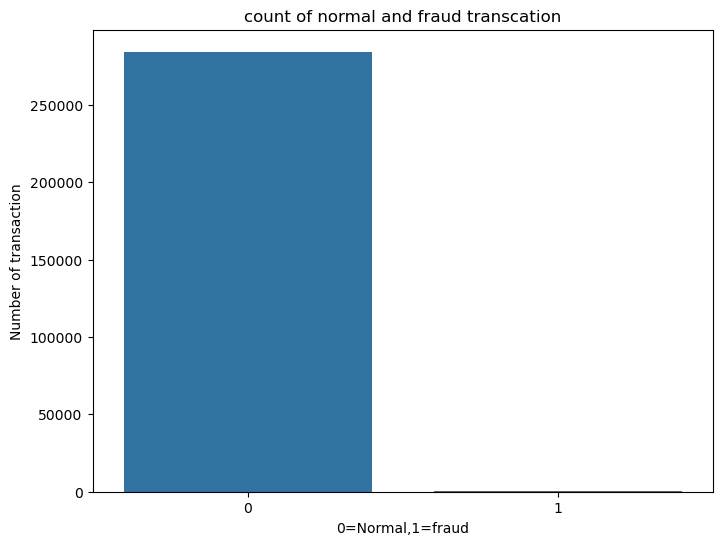

In [7]:
#CountPlot
sns.countplot(x='Class',data=cc)
plt.xlabel("0=Normal,1=fraud")
plt.ylabel("Number of transaction")
plt.title("count of normal and fraud transcation")
plt.show()

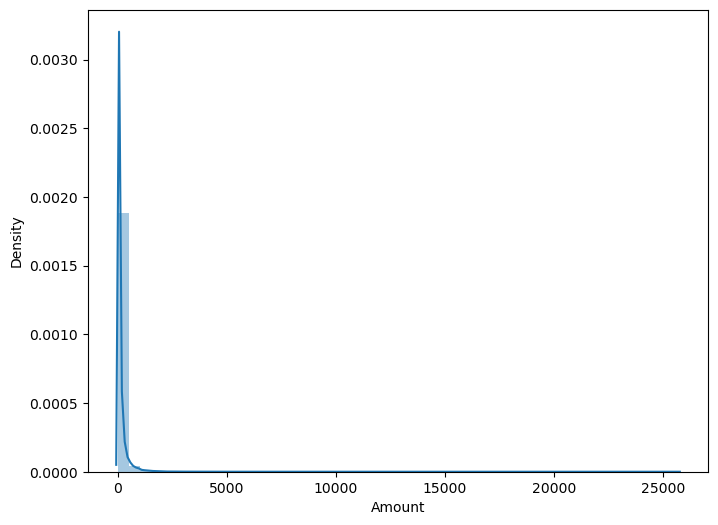

In [12]:
#distplot
sns.distplot(cc['Amount'],hist=True,kde=True)
plt.show()

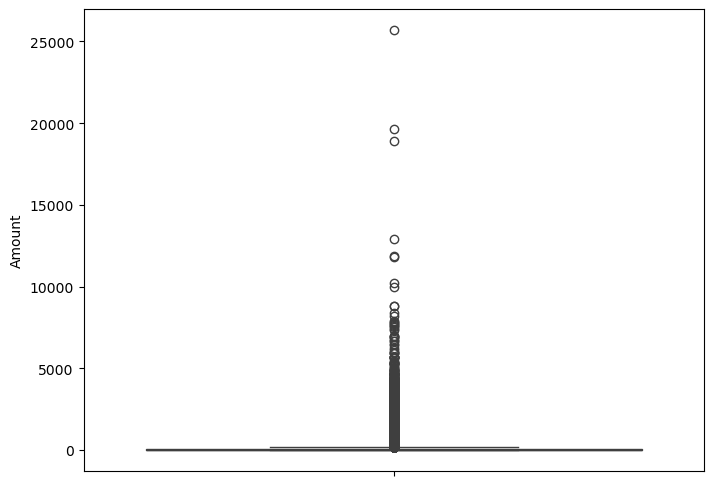

In [4]:
#boxplot
sns.boxplot(cc['Amount'])
plt.show()

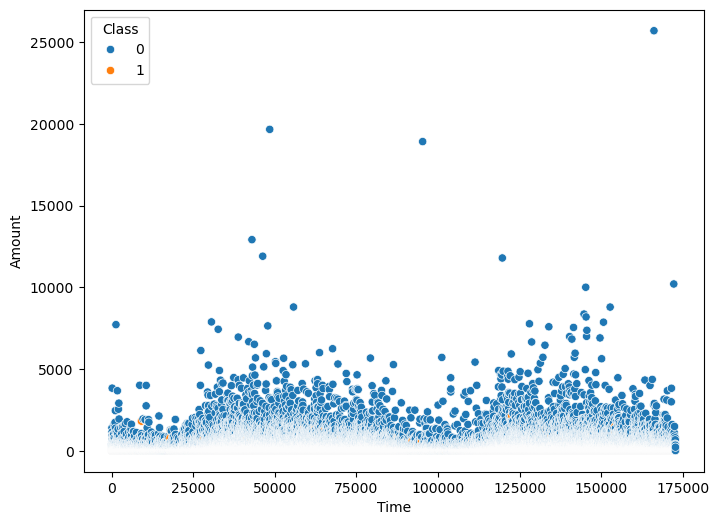

In [5]:
#scatterplot
sns.scatterplot(x='Time', y='Amount',hue='Class', data=cc)
plt.show()

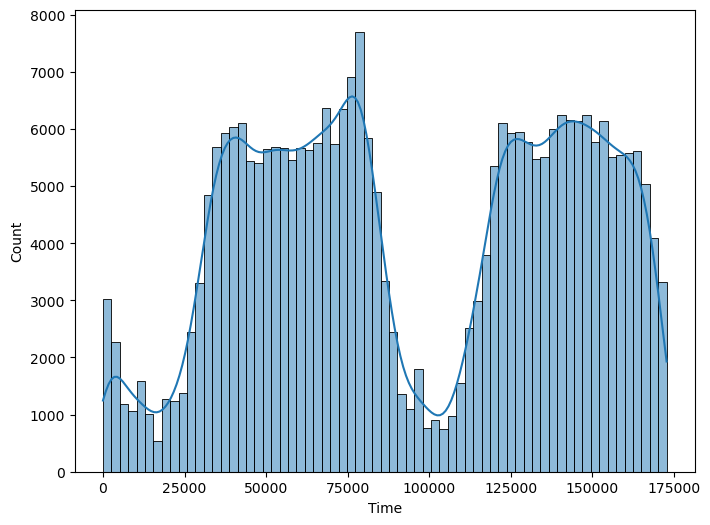

In [7]:
#histplot
sns.histplot(cc['Time'], kde=True)
plt.show()

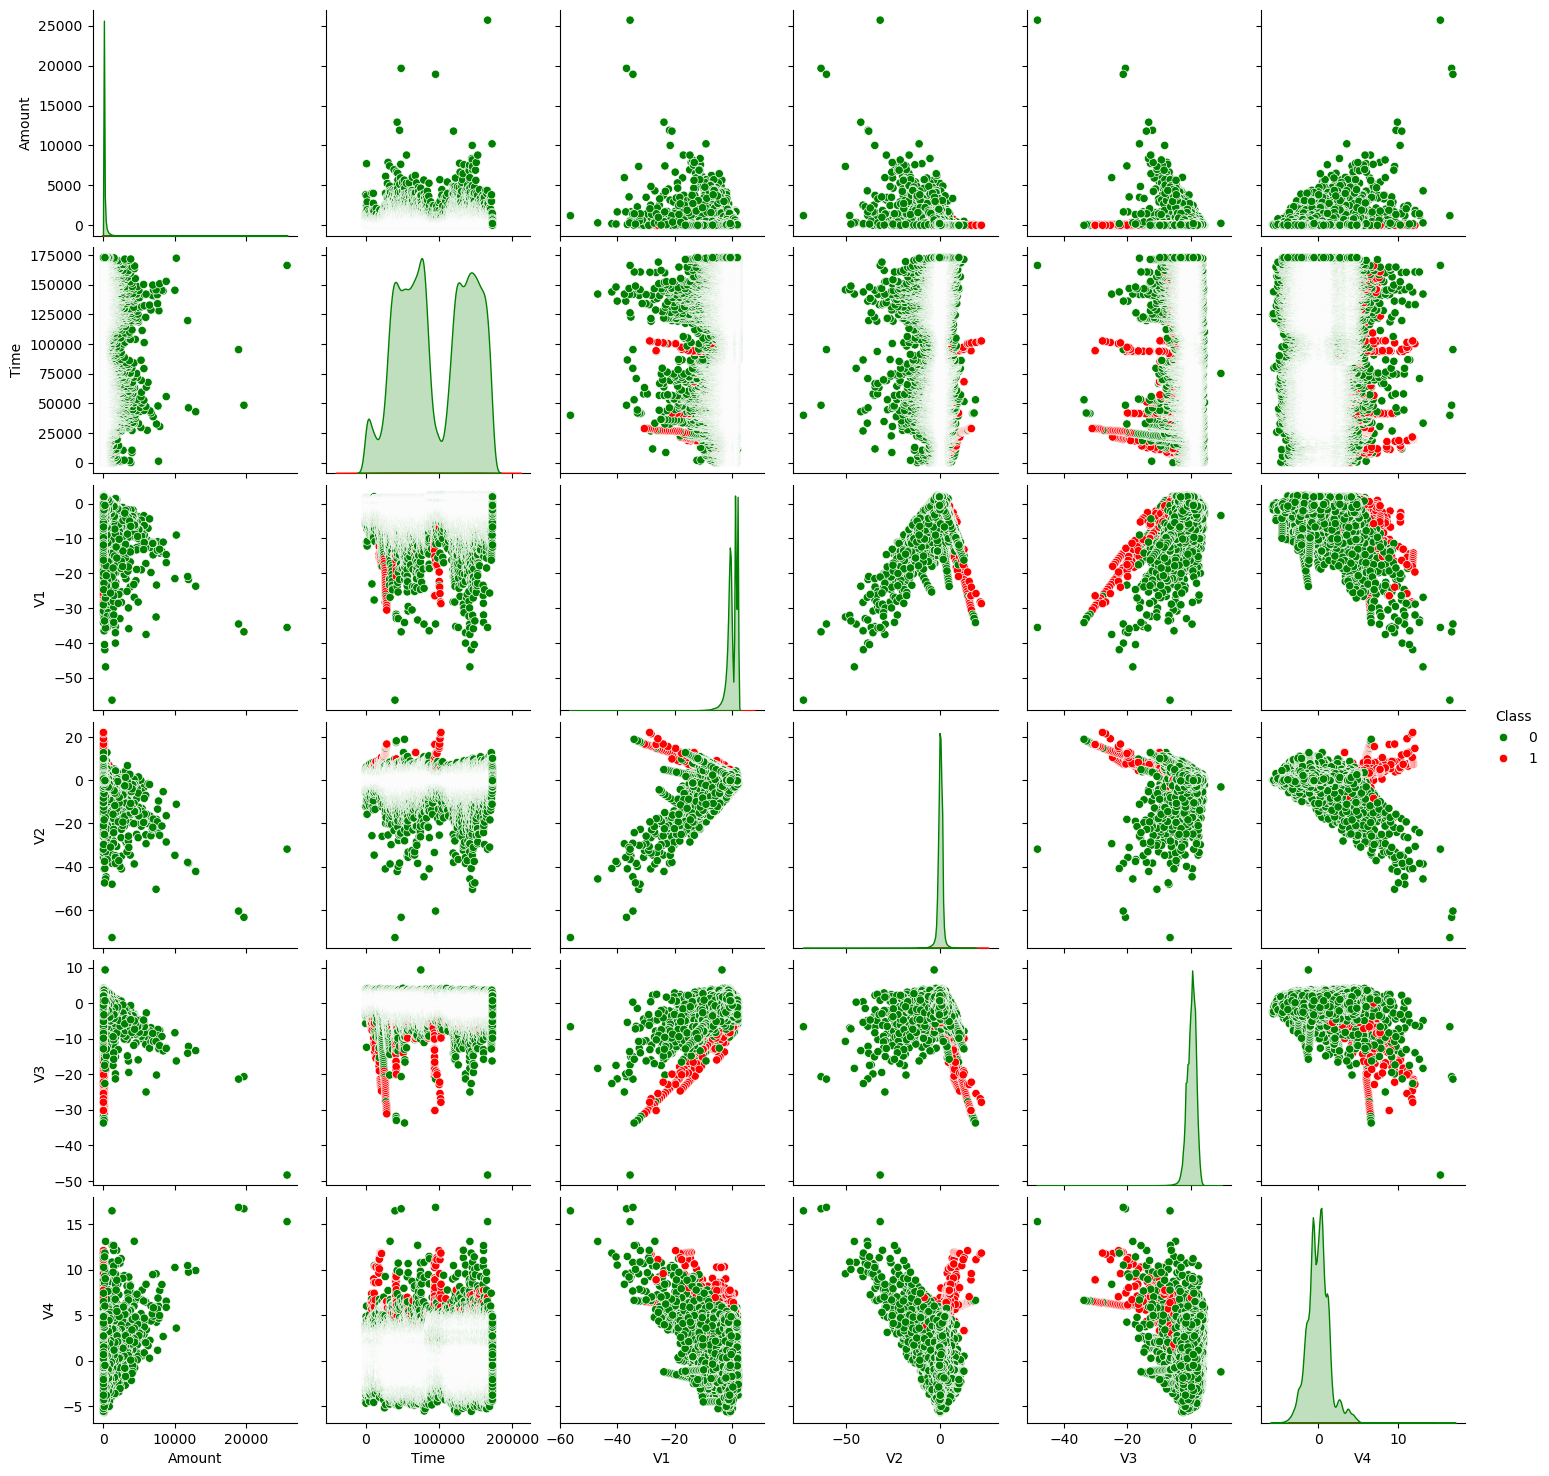

In [4]:
# Pairplot of selected numeric columns
numeric_cols = ['Amount', 'Time', 'V1', 'V2', 'V3', 'V4']  # select few to avoid clutter
sns.pairplot(cc[numeric_cols + ['Class']], hue='Class', palette=['green','red'])
plt.show()

In [ ]:
#Correlion,Skewness & Kurtosis Analysis

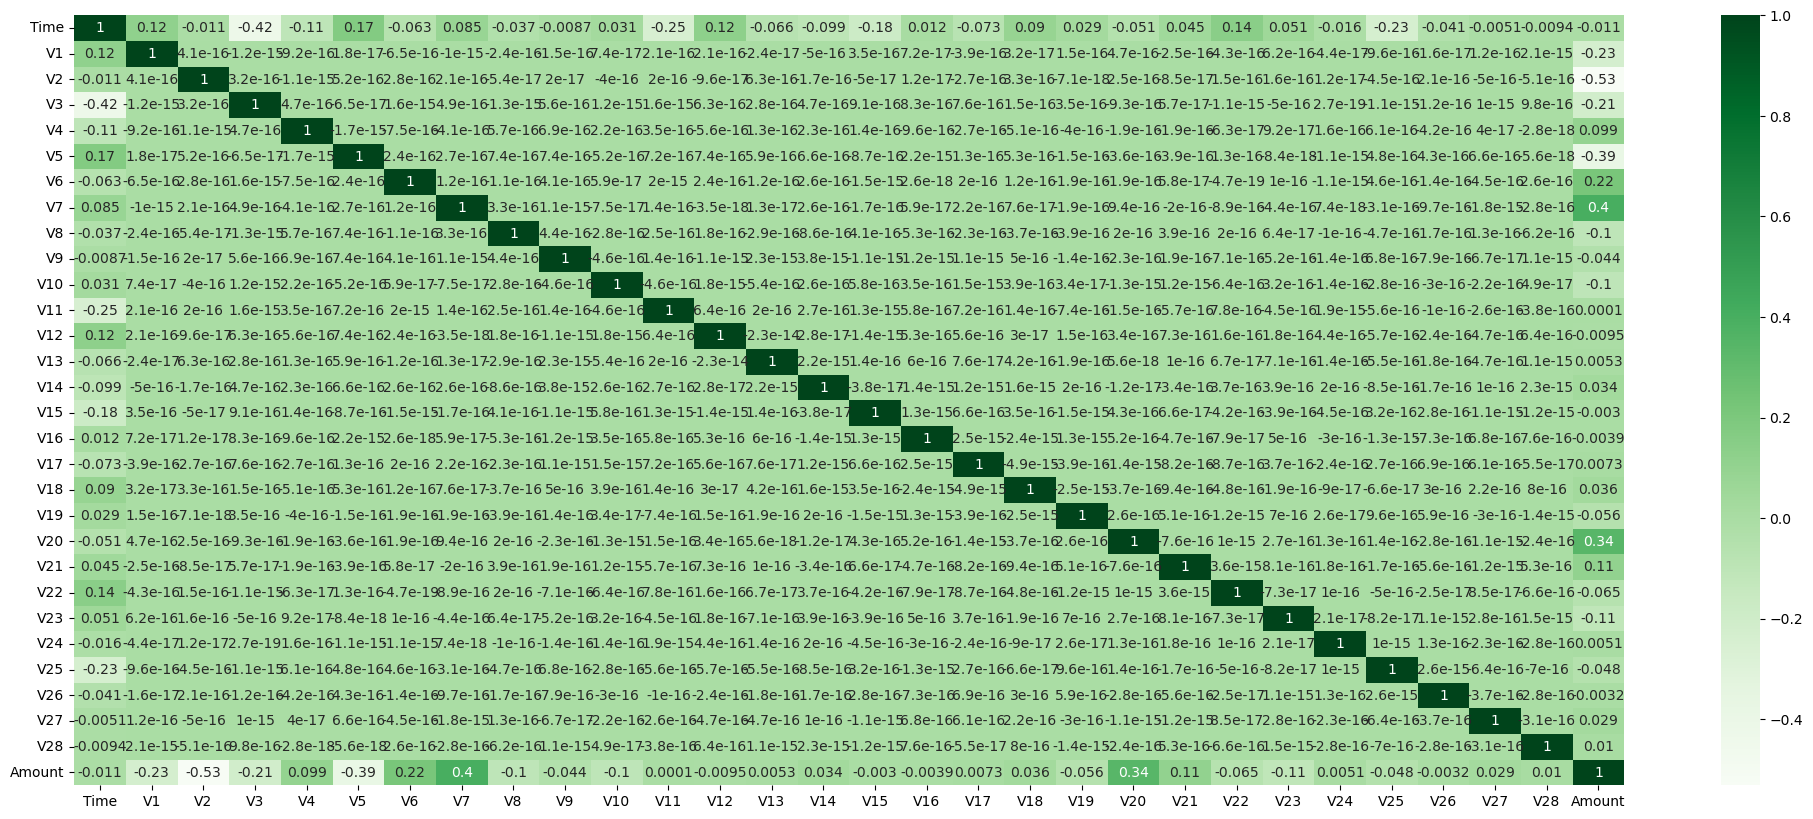

In [9]:
corr=cc[['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9',
 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18',
 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27',
 'V28', 'Amount']].corr()
sns.heatmap(corr, annot=True, cmap='Greens')
plt.show()

In [10]:
sk_col=['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9',
 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18',
 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27',
 'V28', 'Amount']
cc[sk_col].skew()

Time      -0.035568
V1        -3.280667
V2        -4.624866
V3        -2.240155
V4         0.676292
V5        -2.425901
V6         1.826581
V7         2.553907
V8        -8.521944
V9         0.554680
V10        1.187141
V11        0.356506
V12       -2.278401
V13        0.065233
V14       -1.995176
V15       -0.308423
V16       -1.100966
V17       -3.844914
V18       -0.259880
V19        0.109192
V20       -2.037155
V21        3.592991
V22       -0.213258
V23       -5.875140
V24       -0.552499
V25       -0.415793
V26        0.576693
V27       -1.170209
V28       11.192091
Amount    16.977724
dtype: float64

In [11]:
kurt_col=['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9',
 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18',
 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27',
 'V28', 'Amount']
cc[kurt_col].kurt()

Time       -1.293530
V1         32.486679
V2         95.773106
V3         26.619551
V4          2.635455
V5        206.904560
V6         42.642494
V7        405.607417
V8        220.586974
V9          3.731311
V10        31.988239
V11         1.633921
V12        20.241870
V13         0.195300
V14        23.879462
V15         0.284769
V16        10.419131
V17        94.799719
V18         2.578341
V19         1.724970
V20       271.016113
V21       207.287040
V22         2.832967
V23       440.088659
V24         0.618871
V25         4.290412
V26         0.919006
V27       244.989241
V28       933.397502
Amount    845.092646
dtype: float64

In [ ]:
#Model Training

In [3]:
X = cc.drop('Class', axis=1)
y = cc['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
#SMOTE balancing 

In [4]:
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_train, y_train)

# Check new class distribution
from collections import Counter
print(Counter(y_res))

import warnings
# Ignore warnings related to wmic / joblib / loky
warnings.filterwarnings("ignore", message=".*wmic CPU Get NumberOfCores.*")

  File "C:\Users\anu\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\anu\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\anu\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\anu\anaconda3\Lib\subprocess.py", lin

Counter({0: 227451, 1: 227451})

In [ ]:
#Model Building and Evaluation

In [5]:
lr = LogisticRegression(max_iter=1000)
dt = DecisionTreeClassifier(random_state=42)
nb = GaussianNB()

In [6]:
gnb = GaussianNB()
gnb.fit(X_res, y_res)
y_pred = gnb.predict(X_test)

In [7]:
for model in [lr, dt, nb]:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"{model.__class__.__name__} Results:")
    
    from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("-"*50)


LogisticRegression Results:

Confusion Matrix:
 [[56852    12]
 [   43    55]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.82      0.56      0.67        98

    accuracy                           1.00     56962
   macro avg       0.91      0.78      0.83     56962
weighted avg       1.00      1.00      1.00     56962

Precision: 0.8208955223880597

Recall: 0.5612244897959183

--------------------------------------------------

... (8 outputs left out)

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.15      0.63      0.24        98

    accuracy                           0.99     56962
   macro avg       0.57      0.81      0.62     56962
weighted avg       1.00      0.99      1.00     56962

Precision: 0.14622641509433962

Recall: 0.6326530612244898

--------------------------------------------------

In [8]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(dt, X, y, cv=5, scoring='accuracy')
print("Decision Tree CV Accuracy Scores:", scores)
print("Mean CV Accuracy:", scores.mean())


Decision Tree CV Accuracy Scores: [0.00610934 0.99935044 0.99466302 0.99868331 0.99884131]

Mean CV Accuracy: 0.7995294834719185

In [ ]:
#Conclusion
"""
The Credit Card Fraud Detection analysis provides a complete machine learning workflow for handling extremely
imbalanced classification problems. Through descriptive analysis and visualization, we observed strong separation
patterns in PCA-generated features (V1–V28) and heavy imbalance in the target class.
To address this imbalance, SMOTE was applied, successfully balancing the classes. After training multiple models,
the Decision Tree Classifier performed best, achieving high recall (0.79) and balanced precision (0.70) for fraud
detection, as shown in the confusion matrix on page 21. Logistic Regression also performed well with good precision, 
although recall was lower. Gaussian Naive Bayes achieved high recall but low precision.
Overall, the Decision Tree model provides the best trade-off between precision and recall, making it most 
suitable for fraud detection where identifying fraudulent transactions is crucial. This project highlights the importance
of handling imbalanced datasets and demonstrates the effective use of machine learning techniques for financial fraud detection.
"""